Financial institutions process a huge number of transactions every day, making it difficult to manually identify fraudulent transactions. Since fraudulent transactions are extremely rare compared to legitimate ones, a model that simply achieves high accuracy may still fail to detect actual fraud. Therefore, the goal of this project is to develop a machine learning–based fraud detection system that can identify potentially fraudulent transactions while minimizing false positives and false negatives.

In [39]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math as m
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings('ignore')


In [40]:
df = pd.read_csv("../Data/bs140513_032310.csv/bs140513_032310.csv")

In [41]:
df

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0
...,...,...,...,...,...,...,...,...,...,...
594638,179,'C1753498738','3','F','28007','M1823072687','28007','es_transportation',20.53,0
594639,179,'C650108285','4','F','28007','M1823072687','28007','es_transportation',50.73,0
594640,179,'C123623130','2','F','28007','M349281107','28007','es_fashion',22.44,0
594641,179,'C1499363341','5','M','28007','M1823072687','28007','es_transportation',14.46,0


## BankSim Dataset — Variable Descriptions

| Variable | Description |
|---|---|
| `step` | Represents the time granularity of the simulation. Each step corresponds to one day of simulated commercial activity. |
| `customer` | An identifier for the customer involved in the transaction. It helps identify transactions belonging to the same customer. |
| `age` | Represents the customer's age category: `'0'` (18 years or younger), `'1'` (19–25), `'2'` (26–35), `'3'` (36–45), `'4'` (46–55), `'5'` (56–65), `'6'` (over 65), and `'U'` (unknown age). |
| `gender` | Represents the customer's gender category. The documented categories are `E` (Enterprise), `F` (Female), `M` (Male), and `U` (Unknown). |
| `zipcodeOri` | Represents the ZIP code associated with the customer's origin. |
| `merchant` | An identifier for the merchant involved in the transaction. |
| `zipMerchant` | Represents the ZIP code associated with the merchant's location. |
| `category` | Represents the merchant category associated with the purchased goods or services, such as transportation, food, restaurants, or fashion. |
| `amount` | Represents the monetary value of the transaction, measured in euros (€). |
| `fraud` | The binary target variable indicating whether a transaction is fraudulent: `0` = legitimate transaction and `1` = fraudulent transaction. |

### Key Observations

- Each row represents one transaction.
- A customer may have multiple transactions with different merchants.
- `customer` and `merchant` are identifiers, not numerical measurements.
- `age`, `gender`, and `category` are categorical features.
- `amount` represents the transaction value, while `fraud` is the target variable for our prediction task.

**Note:** The dataset is synthetic and simulates financial transactions. We will inspect the actual values and distributions of each column before deciding on data cleaning, encoding, or feature engineering.

In [42]:
df.columns

Index(['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant',
       'zipMerchant', 'category', 'amount', 'fraud'],
      dtype='object')

In [43]:
df.shape

(594643, 10)

In [44]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [45]:
df.tail()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
594638,179,'C1753498738','3','F','28007','M1823072687','28007','es_transportation',20.53,0
594639,179,'C650108285','4','F','28007','M1823072687','28007','es_transportation',50.73,0
594640,179,'C123623130','2','F','28007','M349281107','28007','es_fashion',22.44,0
594641,179,'C1499363341','5','M','28007','M1823072687','28007','es_transportation',14.46,0
594642,179,'C616528518','4','F','28007','M1823072687','28007','es_transportation',26.93,0


In [46]:
df.sample(10)

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
192266,66,'C949319027','2','M','28007','M1823072687','28007','es_transportation',29.61,0
167001,58,'C198230909','4','F','28007','M348934600','28007','es_transportation',53.05,0
487485,151,'C49864446','5','M','28007','M348934600','28007','es_transportation',36.25,0
340621,110,'C165037464','1','F','28007','M85975013','28007','es_food',8.55,0
370334,118,'C642158646','6','F','28007','M348934600','28007','es_transportation',30.61,0
376316,120,'C1767103563','3','F','28007','M85975013','28007','es_food',20.50,0
256360,85,'C1338020899','3','M','28007','M78078399','28007','es_wellnessandbeauty',69.81,0
476633,148,'C1539370210','3','M','28007','M1400236507','28007','es_home',129.09,0
465869,145,'C1575842015','5','M','28007','M1823072687','28007','es_transportation',9.65,0
19039,7,'C358037591','3','M','28007','M348934600','28007','es_transportation',14.32,0


In [47]:
df.isnull().sum().sum()

np.int64(0)

In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB


In [50]:
for col in df.columns:
    print(f"{col} : {df[col].unique()} Unique values\n")

step : [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179] Unique values

customer : ["'C1093826151'" "'C352968107'" "'C2054744914'" ... "'C1014783484'"
 "'C849065220'" "'C1809646275'"] Unique values

age : ["'4'" "'2'" "'3'" "'5'" "'1'" "'6'" "'U'" "'0'"] Unique values

gender : ["'M'" "'F'" "'E'" "'U'"] Unique values


In [51]:
df.dtypes

step             int64
customer        object
age             object
gender          object
zipcodeOri      object
merchant        object
zipMerchant     object
category        object
amount         float64
fraud            int64
dtype: object

In [52]:

df.duplicated().sum()

np.int64(0)

In [53]:
for col in df.columns:
    print(col, ":", df[col].nunique())

step : 180
customer : 4112
age : 8
gender : 4
zipcodeOri : 1
merchant : 50
zipMerchant : 1
category : 15
amount : 23767
fraud : 2


In [54]:
df[['step', 'amount']].describe()

,step,amount
count,594643.000000,594643.000000
mean,94.986827,37.890135
std,51.053632,111.402831
min,0.000000,0.000000
25%,52.000000,13.740000
50%,97.000000,26.900000
75%,139.000000,42.540000
max,179.000000,8329.960000


In [55]:
print("Zero amounts:", (df['amount'] == 0).sum())
print("Negative amounts:", (df['amount'] < 0).sum())
print("Positive amounts:", (df['amount'] > 0).sum())

Zero amounts: 52
Negative amounts: 0
Positive amounts: 594591


In [57]:
df['fraud'].unique()

array([0, 1])

In [56]:
df['fraud'].value_counts(dropna=False)

fraud
0    587443
1      7200
Name: count, dtype: int64

In [59]:
(df['amount'] < 0).sum(), (df['amount'] == 0).sum(), (df['amount'].isna()).sum()

(np.int64(0), np.int64(52), np.int64(0))

In [62]:
df[df['amount'] == 0].head(52)

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
40502,15,'C1918953803','2','F','28007','M348934600','28007','es_transportation',0.0,0
46361,17,'C782199851','2','F','28007','M348934600','28007','es_transportation',0.0,0
48560,18,'C92282564','3','F','28007','M348934600','28007','es_transportation',0.0,0
64613,24,'C612357573','6','M','28007','M348934600','28007','es_transportation',0.0,0
84320,31,'C1299474405','4','F','28007','M348934600','28007','es_transportation',0.0,0
87713,32,'C1814870538','3','M','28007','M1823072687','28007','es_transportation',0.0,0
88889,32,'C1189224644','2','M','28007','M1823072687','28007','es_transportation',0.0,0
89155,32,'C1598762673','3','M','28007','M1823072687','28007','es_transportation',0.0,0
127028,45,'C876944738','2','F','28007','M1823072687','28007','es_transportation',0.0,0
133555,47,'C73919470','3','F','28007','M348934600','28007','es_transportation',0.0,0


In [63]:
df.loc[df['amount']==0, 'fraud'].value_counts()

fraud
0    52
Name: count, dtype: int64

In [64]:
df['customer'].duplicated().sum()

np.int64(590531)

In [65]:
(df.astype(str).apply(lambda col: col.str.strip().eq('').sum()))

step           0
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
amount         0
fraud          0
dtype: int64

In [67]:
df['step'].min(), df['step'].max(), df['step'].isna().sum()

(np.int64(0), np.int64(179), np.int64(0))

In [68]:
df['fraud'].value_counts(dropna=False)

fraud
0    587443
1      7200
Name: count, dtype: int64

In [69]:
df['gender'].unique()

array(["'M'", "'F'", "'E'", "'U'"], dtype=object)

In [70]:
df['age'].unique()

array(["'4'", "'2'", "'3'", "'5'", "'1'", "'6'", "'U'", "'0'"],
      dtype=object)

In [71]:
df['category'].unique()

array(["'es_transportation'", "'es_health'", "'es_otherservices'",
       "'es_food'", "'es_hotelservices'", "'es_barsandrestaurants'",
       "'es_tech'", "'es_sportsandtoys'", "'es_wellnessandbeauty'",
       "'es_hyper'", "'es_fashion'", "'es_home'", "'es_contents'",
       "'es_travel'", "'es_leisure'"], dtype=object)

In [72]:
df['merchant'].unique()

array(["'M348934600'", "'M1823072687'", "'M50039827'", "'M1888755466'",
       "'M1053599405'", "'M85975013'", "'M480139044'", "'M692898500'",
       "'M348875670'", "'M151143676'", "'M840466850'", "'M1741626453'",
       "'M1535107174'", "'M855959430'", "'M349281107'", "'M209847108'",
       "'M2122776122'", "'M1873032707'", "'M2011752106'", "'M857378720'",
       "'M1198415165'", "'M1748431652'", "'M980657600'", "'M1352454843'",
       "'M117188757'", "'M547558035'", "'M17379832'", "'M1649169323'",
       "'M1946091778'", "'M97925176'", "'M923029380'", "'M1353266412'",
       "'M1842530320'", "'M677738360'", "'M1313686961'", "'M732195782'",
       "'M1600850729'", "'M1872033263'", "'M3697346'", "'M495352832'",
       "'M1400236507'", "'M1294758098'", "'M1913465890'", "'M45060432'",
       "'M78078399'", "'M2080407379'", "'M1788569036'", "'M1416436880'",
       "'M933210764'", "'M1726401631'"], dtype=object)

In [73]:
df['zipcodeOri'].unique()

array(["'28007'"], dtype=object)

In [74]:
df['zipMerchant'].unique()

array(["'28007'"], dtype=object)

## Dataset Audit Summary

### 1. Dataset Overview
- **Dataset:** BankSim
- **Rows:** 594,643 transactions
- **Columns:** 10
- **Target variable:** `fraud`
- **Problem type:** Binary classification

### 2. Data Quality Checks
- **Missing values:** No missing values found.
- **Exact duplicate rows:** 0
- **Blank-string values:** None found.
- **Negative transaction amounts:** 0
- **Zero transaction amounts:** 52
- **Zero-amount transaction labels:** All 52 are legitimate transactions (`fraud = 0`).
- **Step range:** 0–179, with no missing values.

### 3. Unique Values and Column Checks
- `step`: 180 unique values
- `customer`: 4,112 unique customer IDs
- `age`: 8 categories
- `gender`: 4 categories
- `zipcodeOri`: 1 unique value (`'28007'`)
- `merchant`: 50 unique merchants
- `zipMerchant`: 1 unique value (`'28007'`)
- `category`: 15 transaction categories
- `amount`: 23,767 unique values
- `fraud`: 2 classes (`0` and `1`)

### 4. Target Variable
- Legitimate transactions (`0`): 587,443
- Fraudulent transactions (`1`): 7,200
- Fraudulent transactions represent approximately **1.21%** of the dataset.
- The target classes are highly imbalanced.

### 5. Audit Decisions
- No rows or columns have been deleted.
- Zero-amount transactions are retained pending further investigation.
- `zipcodeOri` and `zipMerchant` are constant columns and are candidates for removal during preprocessing.
- `age` and `gender` contain documented categorical labels, including `'U'` for unknown.
- BankSim is a synthetic dataset; results should be interpreted accordingly.

### 6. Conclusion
The initial dataset audit found no missing values, exact duplicate rows, blank strings, or negative transaction amounts. However, zero-amount transactions require consideration, two geographic columns are constant, and the target variable is highly imbalanced. These findings will guide the subsequent exploratory data analysis and preprocessing stages.

In [75]:
#UNIVEARIATE ANALYSIS

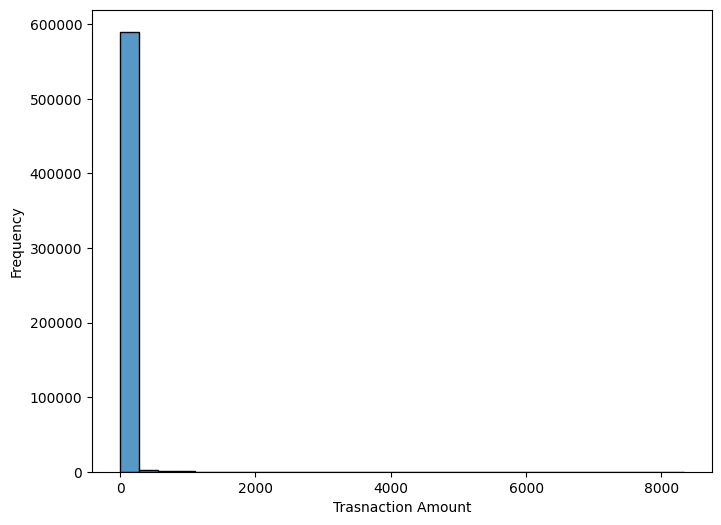

In [77]:
plt.figure(figsize=(8, 6))
sns.histplot(x="amount", data=df, bins=30)
plt.xlabel("Trasnaction Amount")
plt.ylabel("Frequency")
plt.show()

he transaction amount distribution is highly right-skewed, with most transactions having relatively small amounts.

A few transactions have very large amounts, creating a long tail on the right.

Potential outliers will be investigated using the IQR method.

In [81]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = 1.5 - 1.5*IQR
upper_bound = 1.5 + 1.5*IQR

print("IQR: ", IQR)
print("Lower_Bound: ", lower_bound)
print("Upper_Bound: ", upper_bound)

IQR:  28.799999999999997
Lower_Bound:  -41.699999999999996
Upper_Bound:  44.699999999999996


In [90]:
df[df['amount'] > upper_bound].value_counts().sum()

np.int64(133123)

In [93]:
percentage = (133123/594643)*100
print("Percentage: ", percentage)

Percentage:  22.38704567278182


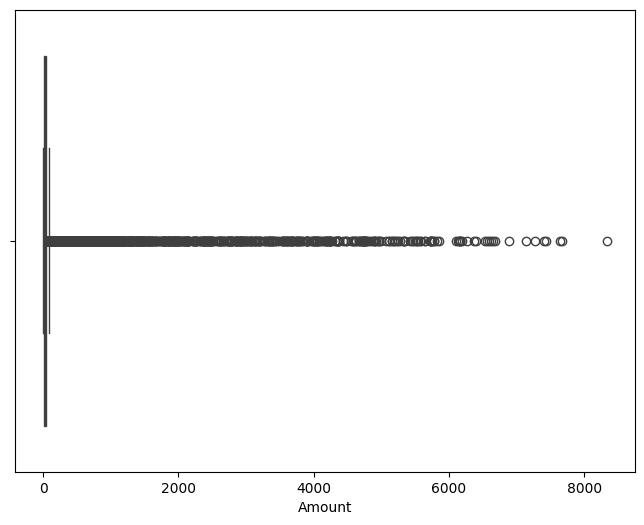

In [96]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="amount", data=df)
plt.xlabel("Amount")
plt.show()

In [99]:
df['amount'].max()

np.float64(8329.96)

In [98]:
df.nlargest(10, 'amount')

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
513394,158,'C702798720','2','M','28007','M732195782','28007','es_travel',8329.96,1
135692,48,'C806399525','2','F','28007','M732195782','28007','es_travel',7665.56,1
383889,122,'C1007572087','2','F','28007','M732195782','28007','es_travel',7635.41,1
6710,2,'C375144053','6','F','28007','M732195782','28007','es_travel',7432.48,1
329533,107,'C430880678','2','M','28007','M2080407379','28007','es_travel',7403.44,1
227774,77,'C1817318774','2','F','28007','M732195782','28007','es_travel',7272.41,1
456821,142,'C350034124','1','F','28007','M2080407379','28007','es_travel',7134.39,1
3744,1,'C1354768768','1','F','28007','M495352832','28007','es_travel',6888.30,1
411290,130,'C751887992','3','F','28007','M732195782','28007','es_travel',6679.23,1
143176,50,'C417267123','2','F','28007','M732195782','28007','es_travel',6649.49,1


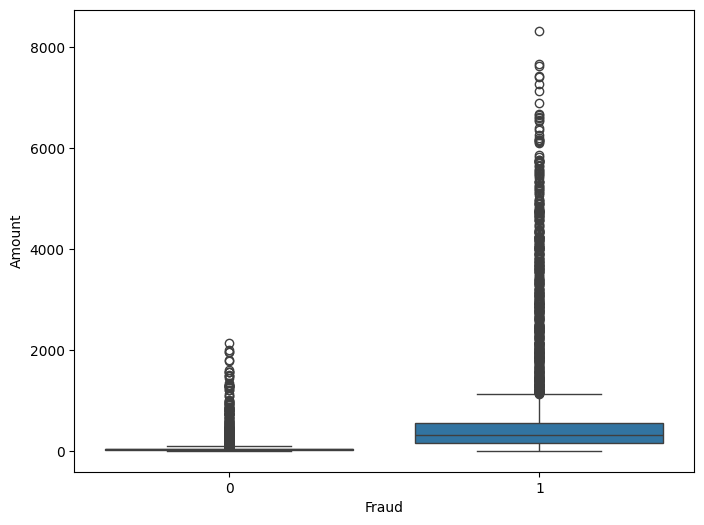

In [100]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="fraud", y="amount", data=df)
plt.xlabel("Fraud")
plt.ylabel("Amount")
plt.show()

In [ ]:
df.groupby("fraud")['amount'].median()

fraud
0     26.610
1    319.175
Name: amount, dtype: float64

In [103]:
df['step'].unique()

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179])

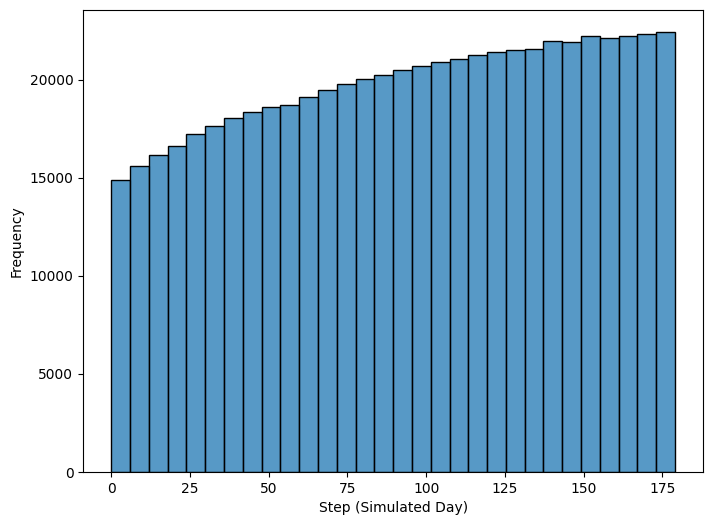

In [104]:
plt.figure(figsize=(8, 6))
sns.histplot(x="step", data=df, bins=30)
plt.xlabel("Step (Simulated Day)")
plt.ylabel("Frequency")
plt.show()

Observation — step distribution
- Transaction frequency gradually increases from step 0 to step 179.
- Later simulated days contain more transactions than earlier days.
- The distribution is not uniform across the 180 steps.

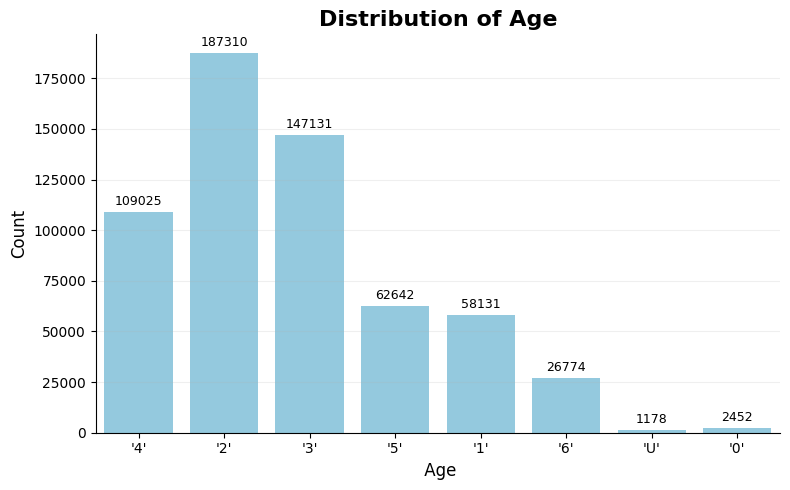

In [110]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['age'],
    color='skyblue'
)

plt.title("Distribution of Age",
          fontsize=16, fontweight='bold')

plt.xlabel(" Age", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Observation — Age distribution
- Age group '2' has the highest transaction count (187,310), followed by '3' (147,131).
- Age group 'U' (unknown) has the lowest count (1,178).
- Transaction records are concentrated in age groups '2', '3', and '4'.

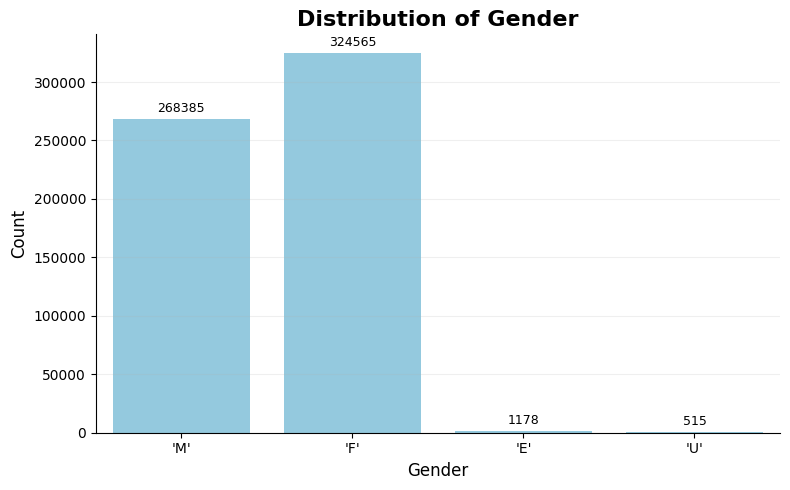

In [111]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df['gender'],
    color='skyblue'
)

plt.title("Distribution of Gender",
          fontsize=16, fontweight='bold')

plt.xlabel("Gender", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Observation — Gender distribution
- Female (F) transactions are highest at 324,565, followed by male (M) transactions at 268,385.
- Enterprise (E) and unknown (U) categories have very few transactions compared with F and M.
- The distribution is heavily concentrated in the female and male categories.

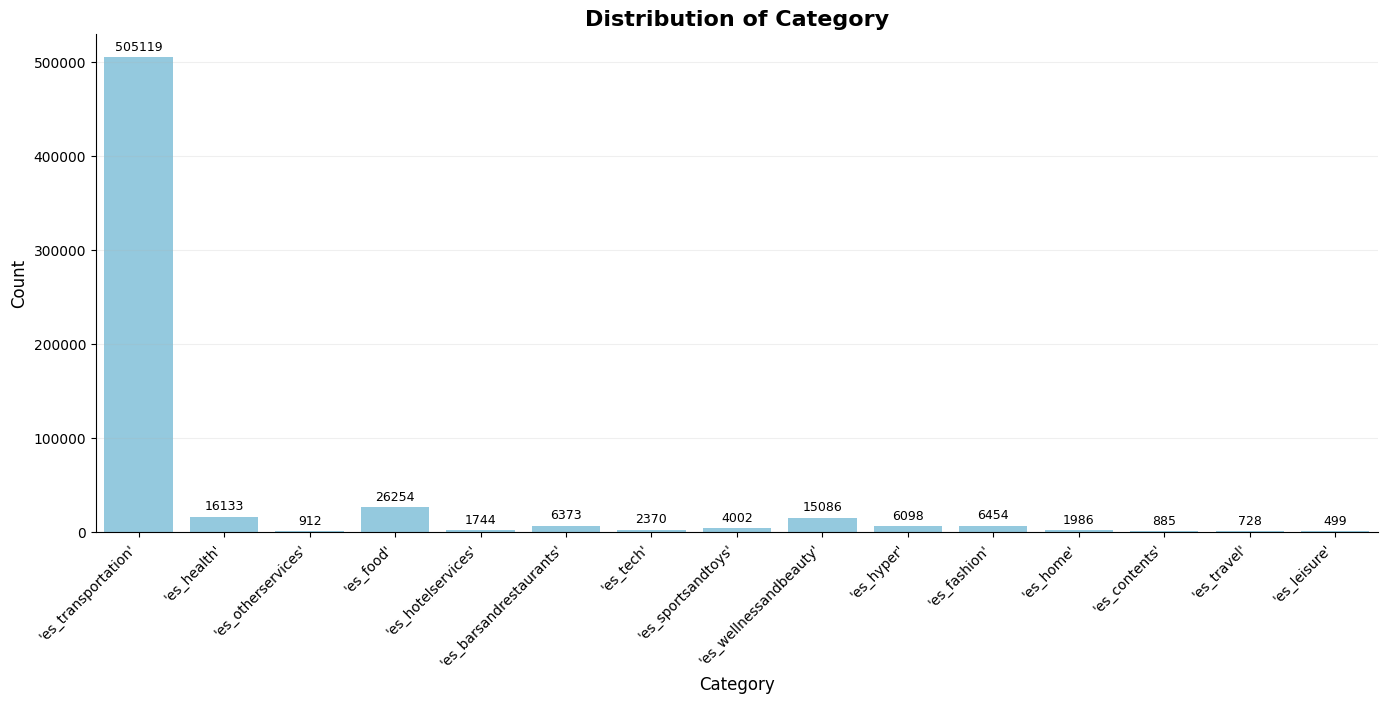

In [120]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    x=df['category'],
    color='skyblue'
)

plt.title("Distribution of Category",
          fontsize=16, fontweight='bold')

plt.xlabel("Category", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.show()

Observation — Category distribution
- es_transportation dominates with 505,119 transactions, far more than any other category.
- es_food (26,254) and es_health (16,133) are the next most frequent categories.
- Categories are highly imbalanced in frequency, with some categories having fewer than 1,000 transactions.

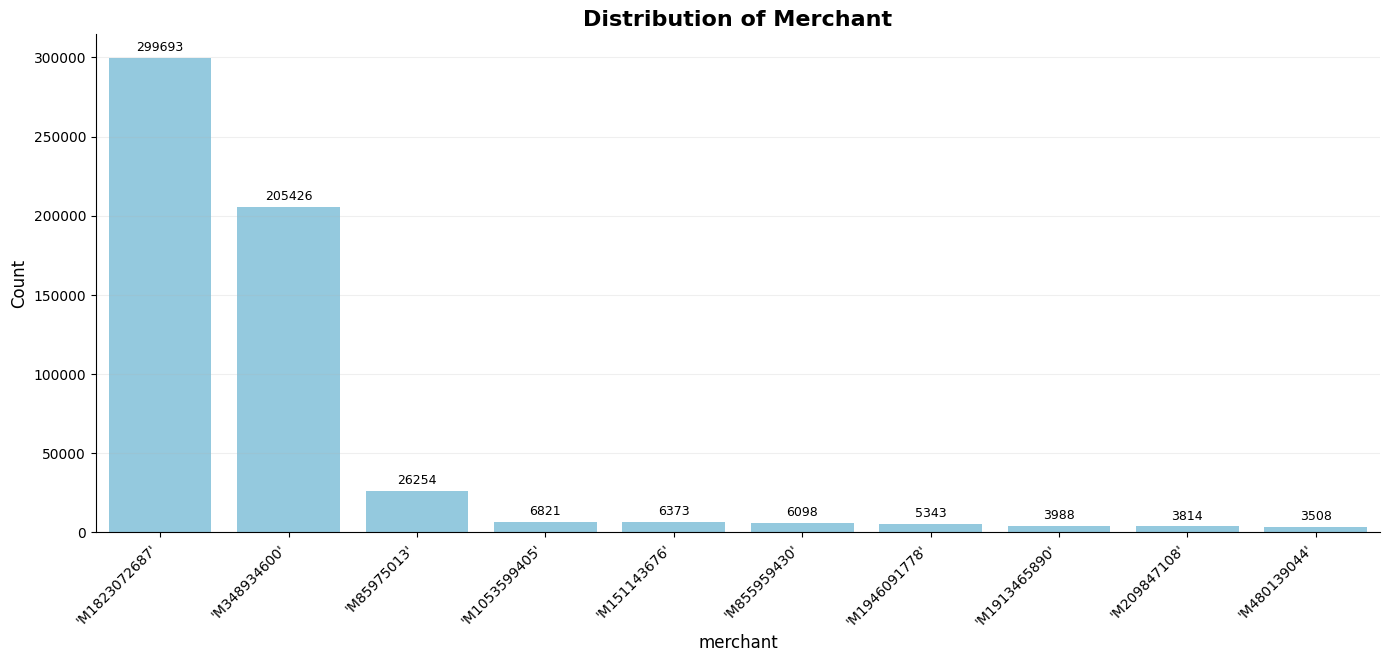

In [129]:
cat = df['merchant'].value_counts().head(10)
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    x=cat.index, y = cat.values, 
    color='skyblue'
)

plt.title("Distribution of Merchant",
          fontsize=16, fontweight='bold')

plt.xlabel("merchant", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.show()

Observation — Merchant distribution
- Merchant 'M1823072687' has the highest transaction count (299,693), followed by 'M348934600' (205,426).
- The remaining top 10 merchants have substantially fewer transactions, indicating that transaction volume is heavily concentrated among two merchants.

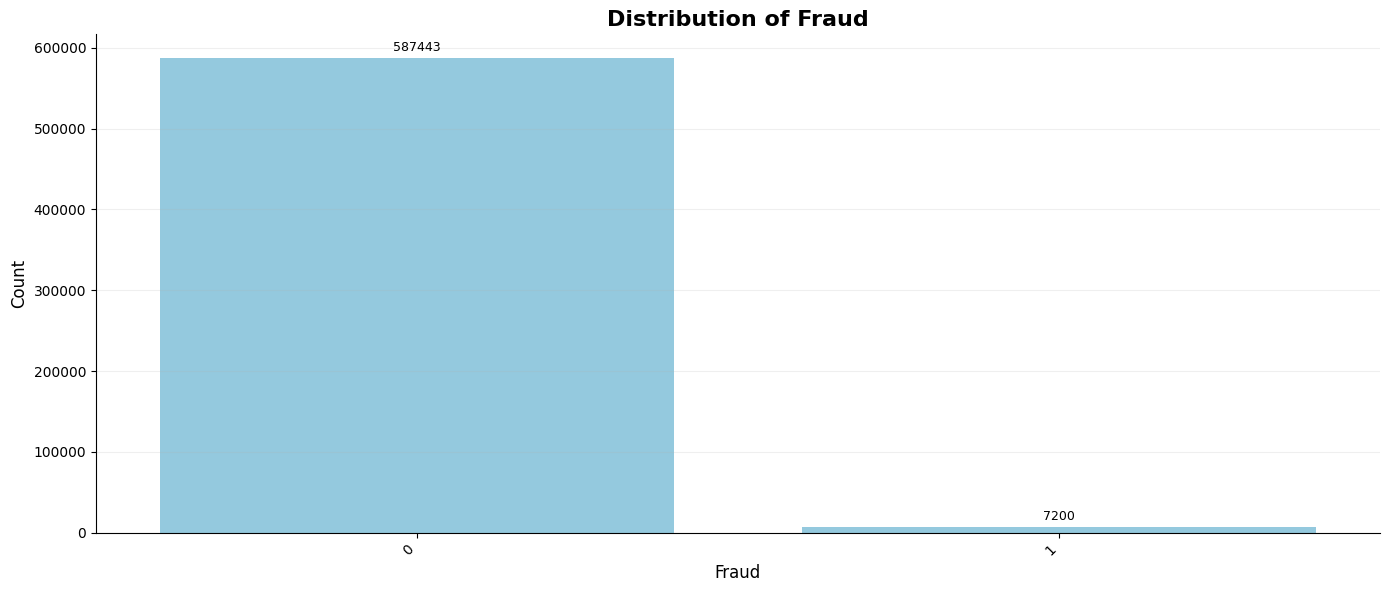

In [130]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    x=df['fraud'],
    color='skyblue'
)

plt.title("Distribution of Fraud",
          fontsize=16, fontweight='bold')

plt.xlabel("Fraud", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.grid(axis='y', alpha=0.2)
sns.despine()

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.show()

Observation — Fraud distribution
- Legitimate transactions (0) account for 587,443, while fraudulent transactions (1) account for only 7,200.
- The dataset is highly imbalanced, with fraud representing approximately 1.21% of all transactions.

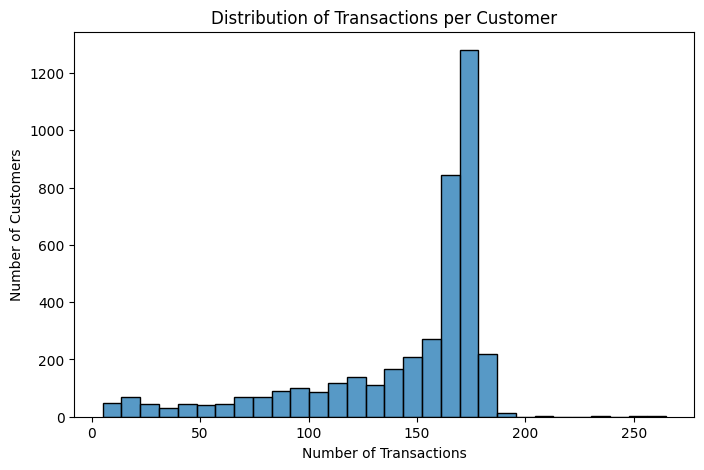

In [135]:
customer_counts = df['customer'].value_counts()

plt.figure(figsize=(8, 5))
sns.histplot(customer_counts, bins=30)
plt.title("Distribution of Transactions per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.show()

Most customers have approximately 160–180 transactions in the dataset.



The distribution is concentrated around 170–180 transactions per customer, with a tail toward lower transaction counts.



A small number of customers have substantially fewer or more transactions than the majority.

## Univariate Analysis Summary

- **Amount:** The distribution is strongly right-skewed, with most transactions having smaller amounts and a few very large values. The IQR method flagged 22.39% of transactions as potential outliers; these were retained for further investigation.
- **Step:** Transaction frequency generally increases across the 180 simulated days.
- **Age:** Age group `'2'` has the highest transaction count, while `'U'` has the lowest.
- **Gender:** Female transactions are more frequent than male transactions. Enterprise and unknown categories occur much less frequently.
- **Category:** `es_transportation` dominates the dataset, accounting for 505,119 transactions.
- **Merchant:** Transaction volume is concentrated among a few merchants, particularly `M1823072687` and `M348934600`.
- **Fraud:** The target is highly imbalanced: 587,443 legitimate transactions and 7,200 fraudulent transactions (approximately 1.21% fraud).
- **Customer activity:** Most customers have approximately 160–180 transactions in the dataset.

**Conclusion:** The dataset shows skewed transaction amounts, uneven category and merchant frequencies, and substantial class imbalance. These characteristics should be considered during feature engineering, model training, and evaluation. No data has been removed or modified during this analysis.